# Assignment 19: Customer Churn Prediction with Model Interpretability (Feature Importance, LIME and SHAP)

In this assignment I build a classification model to predict which telecom customers will churn (leave the company), and then explain how the model makes its decisions. A model that predicts churn is only useful to a business if people can understand and trust why it flags a customer, so I use three interpretability techniques:
- Feature importance: which features matter most overall (global)
- LIME (Local Interpretable Model-agnostic Explanations): why the model made one specific prediction (local)
- SHAP (SHapley Additive exPlanations): how much each feature pushed each prediction up or down, both overall (global) and for one customer (local)

Dataset:
- The Customer Churn dataset provided with the assignment (customer_churn.csv), which is the IBM Telco Customer Churn sample dataset
- Target: Churn (Yes = the customer left, No = the customer stayed)

Steps I will follow:
1. Import libraries and load the data
2. Check the structure, data types and duplicates
3. Split the data into training and test sets
4. Explore the training data
5. Preprocess: handle missing values, encode categories and scale if needed
6. Train and evaluate a classification model
7. Feature importance (built-in and permutation)
8. LIME explanation for one customer
9. SHAP global and local explanations
10. Conclusion

## Step 1: Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

import shap
from lime.lime_tabular import LimeTabularExplainer

pd.set_option("display.max_columns", None)
random_seed = 42
print("shap version:", shap.__version__)

shap version: 0.54.1


## Step 2: Load the Dataset and Check Its Structure

In [3]:
telco = pd.read_csv("customer_churn.csv")

In [4]:
print("Shape:", telco.shape)

Shape: (7043, 21)


In [5]:
display(telco.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
telco.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
print("\nMissing values (NaN):", telco.isnull().sum().sum())


Missing values (NaN): 0


In [8]:
print("Blank TotalCharges values:", (telco["TotalCharges"].str.strip() == "").sum())

Blank TotalCharges values: 11


In [9]:
print("Tenure of customers with blank TotalCharges:", telco.loc[telco["TotalCharges"].str.strip() == "", "tenure"].unique())

Tenure of customers with blank TotalCharges: [0]


In [10]:
print("\nDuplicate rows:", telco.duplicated().sum())


Duplicate rows: 0


In [11]:
dups = telco.drop(columns="customerID").duplicated(keep=False)

In [12]:
print("Duplicate rows ignoring customerID:", telco.drop(columns="customerID").duplicated().sum())

Duplicate rows ignoring customerID: 22


In [13]:
print("Churn distribution:\n", telco["Churn"].value_counts(normalize=True).round(3))

Churn distribution:
 Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [14]:
display(telco[dups].sort_values(["tenure", "MonthlyCharges"]).head(6))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
542,2866-IKBTM,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,8605-ITULD,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
5170,7721-DVEKZ,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
6774,0970-QXPXW,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No
4817,6654-QGBZZ,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.9,No
6706,7878-RTCZG,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.90,19.9,No


### Interpretation: Dataset Structure

The dataset has 7,043 customers and 21 columns. 18 columns are stored as text, mostly Yes/No answers and categories such as contract type and payment method, so they will need to be encoded. Only SeniorCitizen, tenure and MonthlyCharges are numeric.

TotalCharges:
TotalCharges should be a number, but it is stored as text. There are no standard missing values (NaN), but 11 TotalCharges values are blank spaces, which isnull() cannot detect. All 11 of these customers have a tenure of 0 months, meaning they had just joined and had not been billed yet. Their total charges should therefore be 0, so I will set them to 0 and convert the column to numbers.

Duplicates:
There are no exact duplicate rows. Ignoring customerID, 22 rows match other rows. The examples show they are all customers in their first month (tenure 1) with only a basic phone plan, no internet and very similar monthly charges (19.55 to 19.90). This is the simplest and most common profile, so different real customers can easily have identical answers. Because they have different customer IDs and only a few simple features, I will keep them as separate customers.

Target:
26.5% of customers churned and 73.5% stayed. The data is moderately imbalanced, so I will use a stratified split and focus on precision, recall and F1-score for churners, not only accuracy.

## Step 3: Fix TotalCharges and Split the Data into Training and Test Sets

In [15]:
# 1. Blank TotalCharges -> 0 (customers with tenure 0 have not been billed yet), then convert to numbers
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"].str.strip().replace("", "0"))
print("TotalCharges data type:", telco["TotalCharges"].dtype)
print("TotalCharges of tenure-0 customers:", telco.loc[telco["tenure"] == 0, "TotalCharges"].unique())



TotalCharges data type: float64
TotalCharges of tenure-0 customers: [0.]


In [16]:
# 2. Features (X) and target (y)
X = telco.drop(columns=["customerID", "Churn"])
y = (telco["Churn"] == "Yes").astype(int).rename("Churn")


In [17]:

# 3. Train / test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate - train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))


Train: (5634, 19) | Test: (1409, 19)
Churn rate - train: 0.2654 | test: 0.2654


### Interpretation: Fixing TotalCharges and Splitting the Data

I removed the blank spaces in TotalCharges, set the 11 empty values to 0 and converted the column to numbers. It is now a float column, and all customers with a tenure of 0 have total charges of 0. I used 0 instead of the median because these customers had not been billed yet. This is a fixed rule based on the meaning of the data, so it does not cause leakage.

I removed customerID (an identifier) and Churn (the target) from the features, which left 19 features. I converted the target to 1 for customers who churned and 0 for customers who stayed. Then I split the data into 80% training (5,634 customers) and 20% testing (1,409 customers), using stratification. The churn rate is 26.54% in both sets.

## Step 4: Exploratory Data Analysis (Training Data)

In [18]:
train_df = X_train.copy()
train_df["Churn"] = y_train.values

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X_train.columns if c not in num_cols + ["SeniorCitizen"]] + ["SeniorCitizen"]


,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.49,24.57,0.0,9.00,29.00,55.00,72.00
MonthlyCharges,5634.0,64.93,30.14,18.4,35.66,70.50,90.00,118.75
TotalCharges,5634.0,2299.33,2279.20,0.0,402.98,1394.92,3835.82,8684.80


Churn,Stayed,Churned
tenure,37.59,18.36
MonthlyCharges,61.34,74.86
TotalCharges,2564.72,1564.59


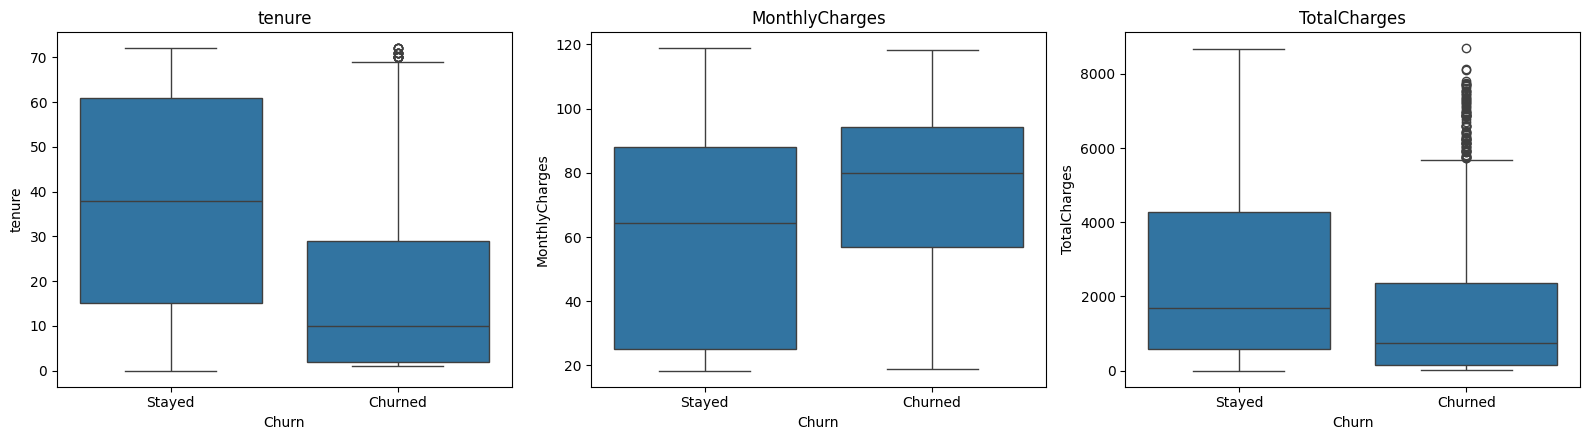

In [19]:
# 1. Numeric summary and averages by churn
display(train_df[num_cols].describe().T.round(2))
display(train_df.groupby("Churn")[num_cols].mean().T.round(2).rename(columns={0: "Stayed", 1: "Churned"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="Churn", y=col, data=train_df, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Stayed", "Churned"]); ax.set_title(col)
plt.tight_layout(); plt.show()


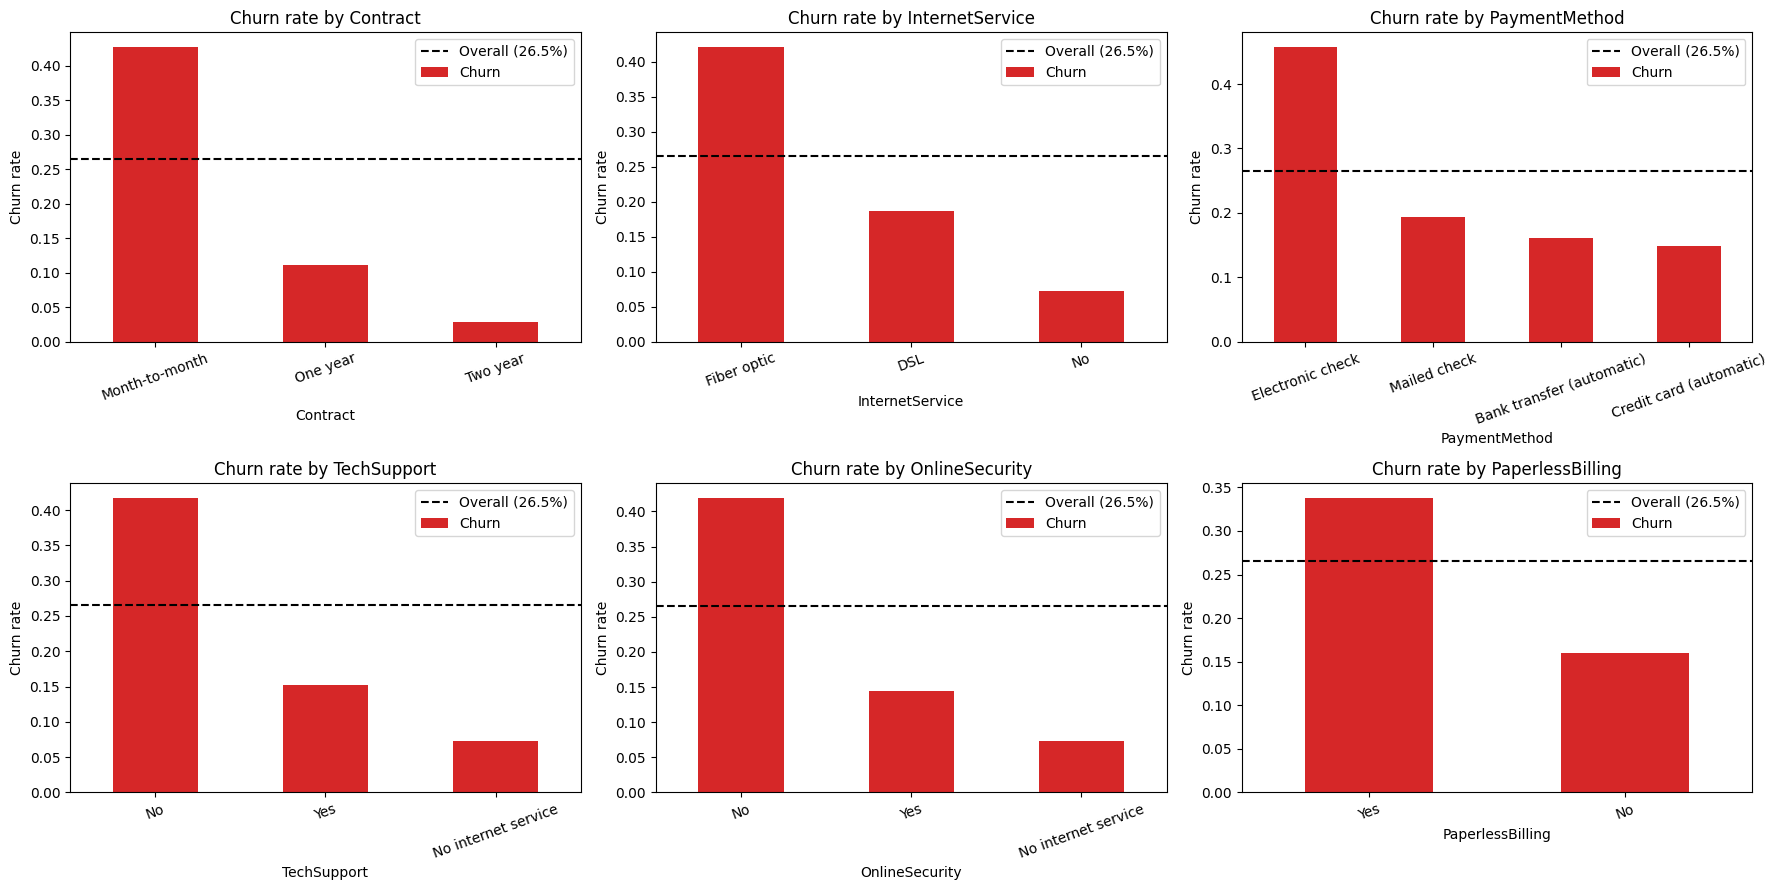

In [20]:
# 2. Churn rate by category
key_cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), key_cats):
    rate = train_df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, rot=20, color="tab:red")
    ax.axhline(y_train.mean(), color="black", linestyle="--", label=f"Overall ({y_train.mean():.1%})")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate"); ax.legend()
plt.tight_layout(); plt.show()

In [21]:
# 3. Churn rate for every categorical feature (table)
for col in cat_cols:
    print(f"{col}: {train_df.groupby(col)['Churn'].mean().round(3).to_dict()}")

gender: {'Female': 0.266, 'Male': 0.264}
Partner: {'No': 0.328, 'Yes': 0.199}
Dependents: {'No': 0.314, 'Yes': 0.152}
PhoneService: {'No': 0.242, 'Yes': 0.268}
MultipleLines: {'No': 0.25, 'No phone service': 0.242, 'Yes': 0.288}
InternetService: {'DSL': 0.187, 'Fiber optic': 0.421, 'No': 0.072}
OnlineSecurity: {'No': 0.419, 'No internet service': 0.072, 'Yes': 0.144}
OnlineBackup: {'No': 0.401, 'No internet service': 0.072, 'Yes': 0.216}
DeviceProtection: {'No': 0.39, 'No internet service': 0.072, 'Yes': 0.228}
TechSupport: {'No': 0.418, 'No internet service': 0.072, 'Yes': 0.152}
StreamingTV: {'No': 0.331, 'No internet service': 0.072, 'Yes': 0.305}
StreamingMovies: {'No': 0.336, 'No internet service': 0.072, 'Yes': 0.3}
Contract: {'Month-to-month': 0.427, 'One year': 0.111, 'Two year': 0.029}
PaperlessBilling: {'No': 0.16, 'Yes': 0.338}
PaymentMethod: {'Bank transfer (automatic)': 0.162, 'Credit card (automatic)': 0.149, 'Electronic check': 0.457, 'Mailed check': 0.193}
SeniorCitizen

### Interpretation: Exploratory Data Analysis

Numeric features:
- Tenure ranges from 0 to 72 months (mean 32.5). Churners have a much shorter tenure: 18.4 months on average compared with 37.6 for customers who stayed, and their median is only about 10 months. New customers are the most likely to leave.
- Monthly charges range from 18.40 to 118.75. Churners pay more per month on average (74.86 compared with 61.34).
- Total charges are lower for churners (1,564.59 compared with 2,564.72), mainly because they have been customers for a shorter time.

Categorical features (churn rate, overall 26.5%):
- Contract is the strongest pattern: 42.7% of month-to-month customers churned, compared with 11.1% on one-year contracts and only 2.9% on two-year contracts.
- Fiber optic internet customers churned the most (42.1%), compared with DSL (18.7%) and no internet (7.2%).
- Customers paying by electronic check churned the most (45.7%). Automatic payments had the lowest churn: bank transfer 16.2% and credit card 14.9%.
- Customers without tech support (41.8%) or online security (41.9%) churned much more than customers with these services (about 15%).
- Senior citizens (41.1%), customers with paperless billing (33.8%), and customers without a partner (32.8%) or dependents (31.4%) also churned more than average.
- Gender has no effect (26.6% for women compared with 26.4% for men), and phone service has almost none.

Overall, the typical churner is a newer customer on a month-to-month contract, with fiber optic internet, no support services, higher monthly charges and paying by electronic check.

Repeated information:
The value "No internet service" appears in six service columns, always with the same churn rate (7.2%), and "No phone service" appears in MultipleLines. This information is already captured by InternetService and PhoneService, so I will merge these values into "No" to avoid repeating the same fact in several features.

## Step 5: Preprocessing – Encoding and Scaling

In [22]:
# 1. Merge repeated "No internet service" / "No phone service" into "No"
X_train_p, X_test_p = X_train.copy(), X_test.copy()
for df in [X_train_p, X_test_p]:
    df.replace({"No internet service": "No", "No phone service": "No"}, inplace=True)

In [23]:
# 2. One-hot encoding (columns learned from training data)
enc_cols = [c for c in cat_cols if c != "SeniorCitizen"]
X_train_p = pd.get_dummies(X_train_p, columns=enc_cols, drop_first=True, dtype=int)
X_test_p = pd.get_dummies(X_test_p, columns=enc_cols, drop_first=True, dtype=int)
X_test_p = X_test_p.reindex(columns=X_train_p.columns, fill_value=0)

In [24]:
print("Missing values - train:", X_train_p.isnull().sum().sum(), "| test:", X_test_p.isnull().sum().sum())
print("Features after encoding:", X_train_p.shape[1])
print(list(X_train_p.columns))

Missing values - train: 0 | test: 0
Features after encoding: 23
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


### Interpretation: Preprocessing

I first merged "No internet service" and "No phone service" into "No", because that information is already contained in InternetService and PhoneService. Then I used one-hot encoding with drop_first=True. Each Yes/No column became a single 0/1 column (for example, TechSupport_Yes), and the multi-category columns became one column per category, compared with a baseline: DSL for InternetService, Month-to-month for Contract, and Bank transfer (automatic) for PaymentMethod. The final data has 23 features with no missing values, and the test set has the same columns as the training set.

I did not scale the numeric features. Random Forest splits on thresholds (for example, "tenure below 12 months"), so feature scales do not affect it. Keeping the original units also makes the LIME and SHAP explanations easier to understand, because they show real values such as months and dollars.

## Step 6: Model Training and Evaluation – Random Forest

Train accuracy: 0.851
Test accuracy:  0.767
Precision: 0.547 | Recall: 0.722 | F1: 0.622 | ROC-AUC: 0.844
5-fold CV - accuracy 0.779 | F1 0.633 | ROC-AUC 0.844

               precision    recall  f1-score   support

      Stayed       0.89      0.78      0.83      1035
     Churned       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



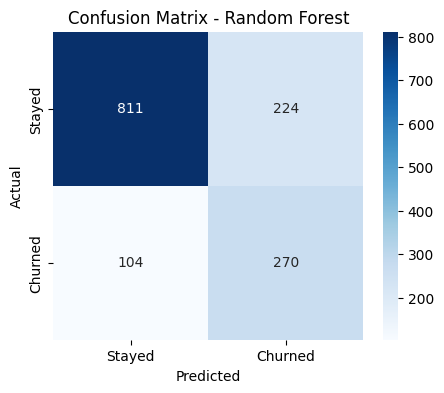

In [25]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                            random_state=random_seed, n_jobs=-1)
rf.fit(X_train_p, y_train)

y_pred = rf.predict(X_test_p)
y_prob = rf.predict_proba(X_test_p)[:, 1]

print("Train accuracy:", round(accuracy_score(y_train, rf.predict(X_train_p)), 3))
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3), "| Recall:", round(recall_score(y_test, y_pred), 3),
      "| F1:", round(f1_score(y_test, y_pred), 3), "| ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

cv = cross_validate(rf, X_train_p, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=random_seed),
                    scoring=["accuracy", "f1", "roc_auc"])
print(f"5-fold CV - accuracy {cv['test_accuracy'].mean():.3f} | F1 {cv['test_f1'].mean():.3f} | ROC-AUC {cv['test_roc_auc'].mean():.3f}")

print("\n", classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix - Random Forest"); plt.show()


### Interpretation: Random Forest Model

I trained a Random Forest with 300 trees, at least 5 customers per leaf (to limit overfitting) and balanced class weights (so mistakes on churners count about 2.8 times more).

Performance:
- Test accuracy is 76.7%, and 5-fold cross-validation accuracy is 77.9%, so the test result is consistent. Training accuracy is 85.1%, so there is some overfitting, but it is moderate.
- For churners, recall is 0.722: the model caught 270 of the 374 customers who actually churned and missed 104.
- Precision is 0.547: of the 494 customers flagged as churners, 270 really churned and 224 were false alarms.
- The F1-score for churners is 0.622 (CV 0.633), and ROC-AUC is 0.844 (CV 0.844), so the model ranks churners well.
- For customers who stayed, precision is 0.89 and recall is 0.78 (811 correctly identified).

Accuracy alone is misleading here: a model that always predicts "stays" would already get 73.5% accuracy but catch no churners. The balanced class weights pushed the model to catch more churners at the cost of more false alarms. For a telecom company, this trade-off is usually acceptable, because contacting a customer who would have stayed (for example, with a retention offer) costs much less than losing a customer.

## Step 7: Feature Importance – Built-in (Random Forest) and Permutation Importance

In [26]:
# 1. Built-in Random Forest importance (Gini)
rf_imp = pd.Series(rf.feature_importances_, index=X_train_p.columns).sort_values(ascending=False)

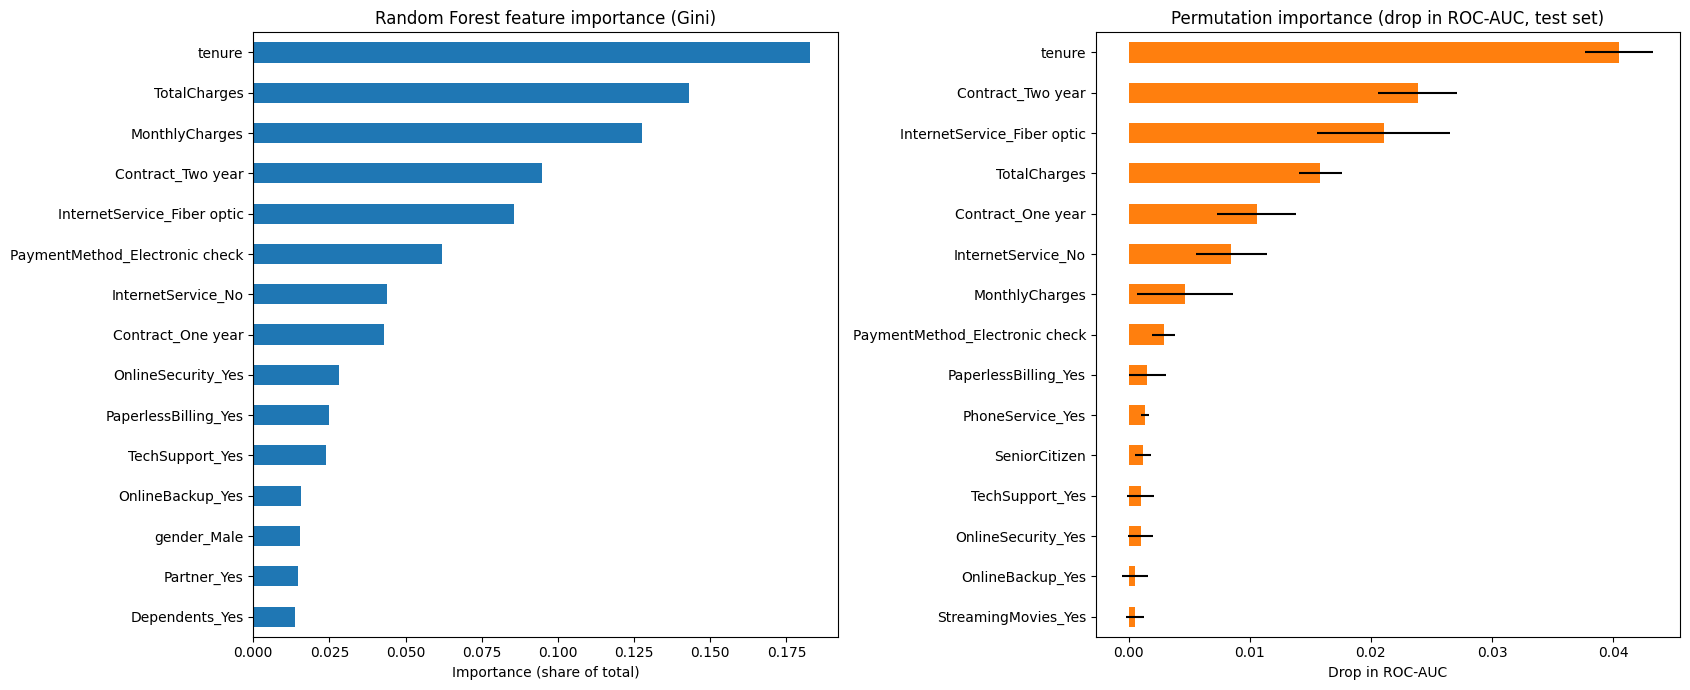

                                Gini importance  Permutation importance  Gini rank  Perm rank
tenure                                    0.183                  0.0405          1          1
TotalCharges                              0.143                  0.0158          2          4
MonthlyCharges                            0.127                  0.0047          3          7
Contract_Two year                         0.095                  0.0239          4          2
InternetService_Fiber optic               0.086                  0.0211          5          3
PaymentMethod_Electronic check            0.062                  0.0029          6          8
InternetService_No                        0.044                  0.0085          7          6
Contract_One year                         0.043                  0.0106          8          5
OnlineSecurity_Yes                        0.028                  0.0010          9         12
PaperlessBilling_Yes                      0.025             

In [27]:
# 2. Permutation importance on the TEST set (drop in ROC-AUC when a feature is shuffled)
perm = permutation_importance(rf, X_test_p, y_test, scoring="roc_auc", n_repeats=10,
                              random_state=random_seed, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test_p.columns).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=X_test_p.columns)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
rf_imp.head(15).sort_values().plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("Random Forest feature importance (Gini)"); axes[0].set_xlabel("Importance (share of total)")
top_perm = perm_imp.head(15).sort_values()
top_perm.plot(kind="barh", xerr=perm_std[top_perm.index], ax=axes[1], color="tab:orange")
axes[1].set_title("Permutation importance (drop in ROC-AUC, test set)"); axes[1].set_xlabel("Drop in ROC-AUC")
plt.tight_layout(); plt.show()

imp_table = pd.DataFrame({"Gini importance": rf_imp.round(3), "Permutation importance": perm_imp.round(4)})
imp_table["Gini rank"] = imp_table["Gini importance"].rank(ascending=False).astype(int)
imp_table["Perm rank"] = imp_table["Permutation importance"].rank(ascending=False).astype(int)
print(imp_table.sort_values("Gini rank").head(10).to_string())

### Interpretation: Feature Importance

I compared the Random Forest's built-in importance (based on how much each feature reduces Gini impurity) with permutation importance (how much ROC-AUC drops on the test set when a feature is shuffled).

Most influential features:
- Tenure is the most important feature in both methods (Gini 0.183, permutation 0.041). How long someone has been a customer is the strongest predictor: new customers are much more likely to churn.
- Contract type is the next most important. Contract_Two year is 2nd in permutation importance (0.024) and Contract_One year is 5th. Long contracts strongly reduce churn, matching the EDA (42.7% churn for month-to-month compared with 2.9% for two-year contracts).
- InternetService_Fiber optic is 3rd in permutation importance (0.021). Fiber customers churn much more often.
- TotalCharges (2nd in Gini, 4th in permutation) and MonthlyCharges (3rd in Gini, 7th in permutation) also matter, along with InternetService_No and PaymentMethod_Electronic check.

Differences between the methods:
Gini importance ranks the continuous features (tenure, TotalCharges and MonthlyCharges) as the top three, partly because continuous features offer many possible split points. Permutation importance, which measures the real effect on new data, ranks the contract and fiber optic features higher and MonthlyCharges lower (7th). MonthlyCharges overlaps with other features: fiber optic is the expensive service, and TotalCharges is roughly tenure multiplied by MonthlyCharges. Gini importance also lists gender_Male, Partner_Yes and Dependents_Yes in its top 15, while permutation importance does not. The EDA showed gender has no effect on churn (26.6% compared with 26.4%), so this is an example of Gini importance overrating features the trees use for small, unimportant splits.

Overall, both methods agree that tenure, contract type and

## Step 8: LIME – Explaining an Individual Prediction

In [28]:
# 1. Choose an instance: a correctly predicted churner with high churn probability
results = pd.DataFrame({"actual": y_test.values, "predicted": y_pred, "prob_churn": y_prob}, index=X_test_p.index)
tp = results[(results["actual"] == 1) & (results["predicted"] == 1)]
idx = tp["prob_churn"].sort_values(ascending=False).index[0]
pos = X_test_p.index.get_loc(idx)          # position of this customer in X_test_p
print(f"Chosen customer (row {idx}) - actual: churned | predicted churn probability: {results.loc[idx, 'prob_churn']:.3f}")
display(X_test.loc[[idx]])                 # original, readable values

Chosen customer (row 4585) - actual: churned | predicted churn probability: 0.969


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,No,No,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05


In [29]:
# 2. LIME explainer (trained on the TRAINING data distribution)
dummy_idx = [i for i, c in enumerate(X_train_p.columns) if X_train_p[c].isin([0, 1]).all()]
explainer = LimeTabularExplainer(training_data=X_train_p.values,
                                 feature_names=X_train_p.columns.tolist(),
                                 class_names=["Stayed", "Churned"],
                                 categorical_features=dummy_idx,
                                 mode="classification", random_state=random_seed)

lime_exp = explainer.explain_instance(X_test_p.iloc[pos].values, rf.predict_proba, num_features=10)

C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


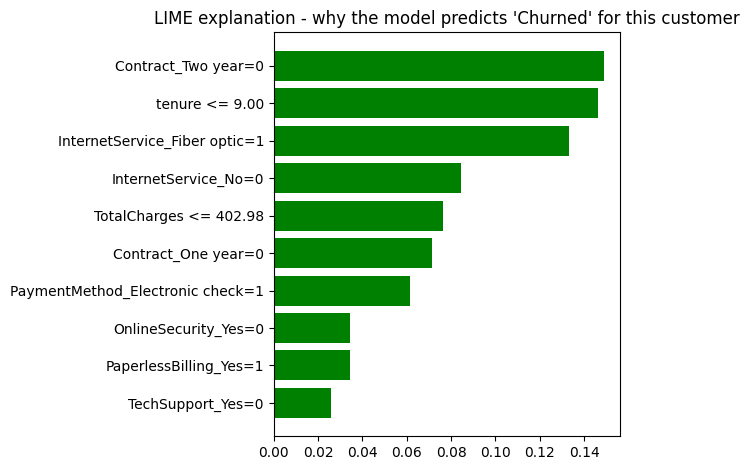

Feature contributions (positive = pushes towards churn):
  Contract_Two year=0                           +0.149
  tenure <= 9.00                                +0.146
  InternetService_Fiber optic=1                 +0.133
  InternetService_No=0                          +0.084
  TotalCharges <= 402.98                        +0.076
  Contract_One year=0                           +0.072
  PaymentMethod_Electronic check=1              +0.061
  OnlineSecurity_Yes=0                          +0.034
  PaperlessBilling_Yes=1                        +0.034
  TechSupport_Yes=0                             +0.026


In [30]:
# 3. Visualize
fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME explanation - why the model predicts 'Churned' for this customer"); plt.tight_layout(); plt.show()

print("Feature contributions (positive = pushes towards churn):")
for feat, w in lime_exp.as_list(label=1):
    print(f"  {feat:<45} {w:+.3f}")

### Interpretation: LIME Explanation for One Customer

I chose the customer the model was most confident would churn, and who actually did churn (a correct prediction). LIME created many slightly changed versions of this customer, checked how the Random Forest's prediction changed, and fitted a simple local model to show which features drove this prediction.

All 10 features shown push the prediction towards "Churned" (green bars):
- Contract_Two year = 0 (+0.149) and Contract_One year = 0 (+0.072): the customer is on a month-to-month contract, which makes it easy to leave.
- tenure <= 9 months (+0.146): the customer is new. New customers are the most likely to churn.
- InternetService_Fiber optic = 1 (+0.133) and InternetService_No = 0 (+0.084): the customer has fiber optic internet, the service with the highest churn rate.
- TotalCharges <= 402.98 (+0.076): low total spending so far, which also reflects a short time with the company.
- PaymentMethod_Electronic check = 1 (+0.061): customers paying by electronic check churn the most.
- OnlineSecurity_Yes = 0 (+0.034), TechSupport_Yes = 0 (+0.026) and PaperlessBilling_Yes = 1 (+0.034): no add-on services that tend to keep customers.

The two strongest reasons are the lack of a long contract and the short tenure, followed by fiber optic internet. This matches the global feature importance and the EDA, so the model's reasoning for this customer is sensible. From a business point of view, this customer could have been targeted with an offer to switch to a one- or two-year contract, automatic payment, or a free tech support or online security trial.

The model gave this customer a very high churn probability.

## Step 9: SHAP – Global and Local Interpretability

In [31]:
# 1. SHAP values for every test customer (TreeExplainer = fast and exact for tree models)
shap_explainer = shap.TreeExplainer(rf)
shap_exp = shap_explainer(X_test_p)
sv_churn = shap_exp[:, :, 1]               # SHAP values for the "Churned" class
print("SHAP values shape (customers x features):", sv_churn.values.shape)
print("Base value (average predicted churn probability):", round(float(sv_churn.base_values[0]), 3))

SHAP values shape (customers x features): (1409, 23)
Base value (average predicted churn probability): 0.499


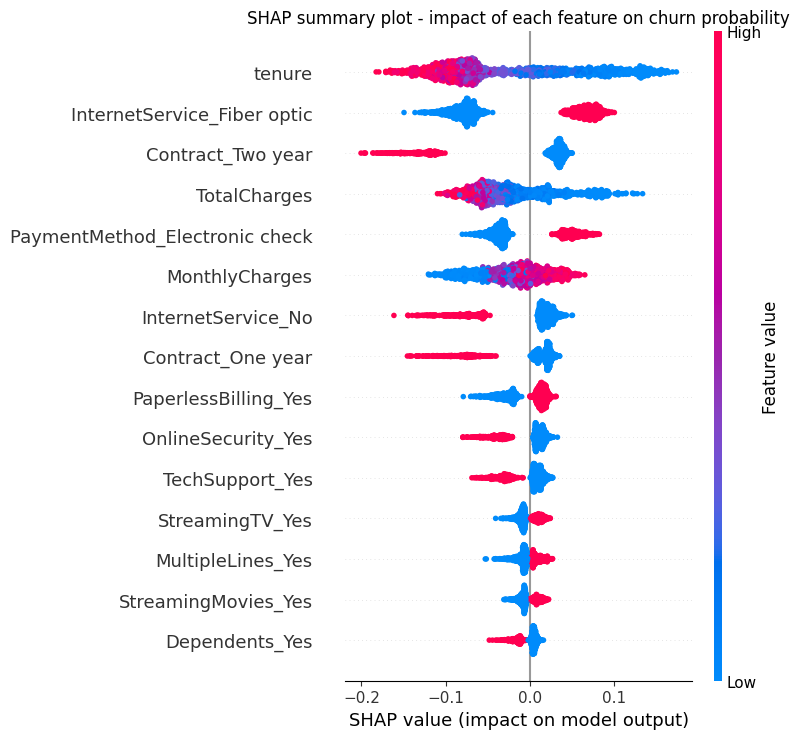

In [32]:
# 2. GLOBAL: summary (beeswarm) plot
shap.summary_plot(sv_churn.values, X_test_p, max_display=15, show=False)
plt.title("SHAP summary plot - impact of each feature on churn probability"); plt.tight_layout(); plt.show()



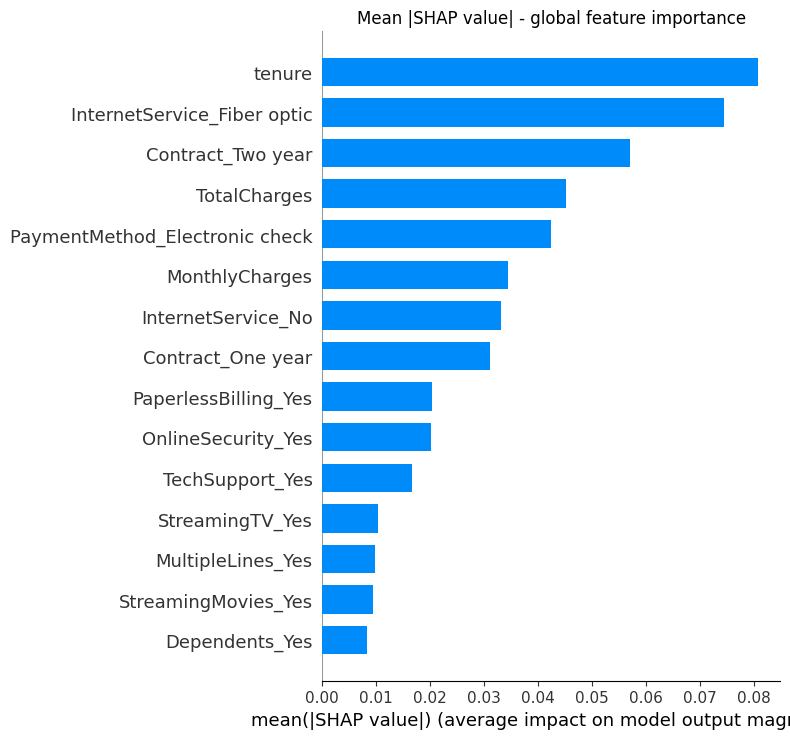

In [33]:
# 3. GLOBAL: mean absolute SHAP value (bar)
shap.summary_plot(sv_churn.values, X_test_p, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP value| - global feature importance"); plt.tight_layout(); plt.show()

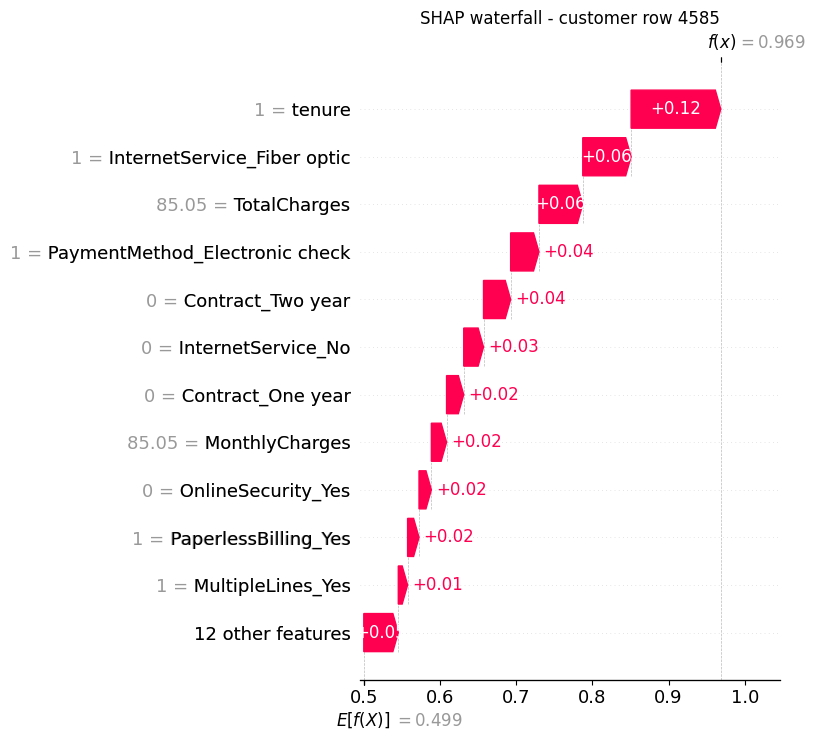

In [34]:
# 4. LOCAL: waterfall plot for the SAME customer as LIME
shap.plots.waterfall(sv_churn[pos], max_display=12, show=False)
plt.title(f"SHAP waterfall - customer row {idx}"); plt.tight_layout(); plt.show()

In [35]:
# Check: base value + sum of SHAP values = model's predicted probability
check = sv_churn.base_values[pos] + sv_churn.values[pos].sum()
print(f"Base + sum of SHAP values = {check:.3f} | Model probability = {y_prob[pos]:.3f}")

Base + sum of SHAP values = 0.969 | Model probability = 0.969


### Interpretation: SHAP Global and Local Explanations

SHAP calculated a value for each of the 23 features for each of the 1,409 test customers, showing how much each feature pushed that customer's churn probability up or down. The base value (the model's average predicted churn probability) is 0.499. This is higher than the real churn rate (26.5%), because I trained the model with balanced class weights, which treats both classes as equally common.

Global explanation (summary and bar plots):
The most important features by average absolute SHAP value are tenure, InternetService_Fiber optic, Contract_Two year, TotalCharges, PaymentMethod_Electronic check and MonthlyCharges. This ranking is very close to the permutation importance from Step 7, and gender does not appear in the top features, unlike the Gini importance. The summary plot also shows the direction of each effect:
- Tenure: low tenure (blue dots) pushes strongly towards churn, and long tenure (red) pushes towards staying.
- Fiber optic: having fiber (red) increases churn.
- Contract_Two year: having a two-year contract (red) gives the strongest single push towards staying (about -0.2).
- Low TotalCharges, electronic check payments, higher monthly charges and paperless billing push towards churn.
- Having no internet service, a one-year contract, online security, tech support or dependents pushes towards staying.

Local explanation (waterfall plot):
For the same customer I explained with LIME (row 4585), the model predicts a churn probability of 0.969. Starting from the base value of 0.499, the biggest increases come from tenure = 1 month (+0.12), fiber optic internet (+0.06), total charges of only 85.05 (+0.06), paying by electronic check (+0.04) and not having a two-year contract (+0.04). Smaller increases come from no one-year contract, no online security, paperless billing and higher monthly charges. The customer had just joined, was on a month-to-month fiber plan and had only received their first bill.

Comparison with LIME:
SHAP and LIME agree on the main reasons for this prediction (short tenure, no long contract, fiber optic, low total charges and electronic check), but they rank them slightly differently: LIME puts "no two-year contract" first, while SHAP puts tenure first. LIME fits an approximate local model on randomly changed samples, so its weights can vary. SHAP values add up exactly to the prediction: the base value of 0.499 plus all SHAP values equals 0.969, the model's predicted probability, which my check confirmed.

## Step 10: Conclusion – Model Performance and Interpretability

### Model performance
I trained a Random Forest (300 trees, minimum 5 customers per leaf, balanced class weights) to predict churn for 7,043 telecom customers. On the test set it reached 76.7% accuracy, recall of 0.722 for churners (270 of 374 caught), precision of 0.547, an F1-score of 0.622 and a ROC-AUC of 0.844, consistent with 5-fold cross-validation. Balanced class weights made the model catch more churners at the cost of more false alarms, which is a sensible trade-off when losing a customer costs more than a retention offer.

### What drives churn (all three methods agree)

| Rank | Gini importance | Permutation importance | Mean SHAP |
|---|---|---|---|
| 1 | tenure | tenure | tenure |
| 2 | TotalCharges | Contract_Two year | InternetService_Fiber optic |
| 3 | MonthlyCharges | InternetService_Fiber optic | Contract_Two year |
| 4 | Contract_Two year | TotalCharges | TotalCharges |
| 5 | InternetService_Fiber optic | Contract_One year | PaymentMethod_Electronic check |

- **Tenure** is the strongest driver: new customers are the most likely to leave.
- **Contract type** is next: month-to-month customers churn far more, and two-year contracts strongly prevent churn.
- **Fiber optic internet** and **electronic check payments** increase churn.
- **Online security and tech support** reduce churn.
- **Gender has no real effect.** Gini importance overrated it, while permutation importance and SHAP correctly ignored it.

### Comparing the interpretability methods

| Method | Scope | Strength | Limitation |
|---|---|---|---|
| Gini feature importance | Global | Instant, built into Random Forest | Favours continuous features; no direction; overrated gender |
| Permutation importance | Global | Measures the real effect on test data; works for any model | Slower; correlated features can share or hide importance |
| LIME | Local | Easy-to-read rules (e.g. "tenure <= 9") for one customer | Approximate; weights can change between runs |
| SHAP | Global and local | Exact values that add up to the prediction; shows size and direction | Slower; the base value reflects the class weights (0.499), not the real churn rate |

For the explained customer (tenure 1 month, fiber optic, month-to-month, electronic check, churn probability 96.9%), LIME and SHAP gave the same main reasons, which builds trust that the model's reasoning is sensible and matches the business patterns found in the EDA.

### Business recommendations
1. Focus retention efforts on **new customers** (first months of tenure) and **month-to-month** customers.
2. Encourage customers to move to **one- or two-year contracts**, for example with discounts.
3. Promote **automatic payment methods** instead of electronic checks.
4. Offer **online security and tech support** (for example, free trials), especially to fiber optic customers.
5. Investigate why **fiber optic customers** churn more (price, service quality or competition).

### Conclusion
The Random Forest predicts churn reasonably well (ROC-AUC 0.844), and the interpretability techniques make it trustworthy and useful: they explain *why* customers are likely to leave, globally and for individual customers. SHAP gave the most complete and reliable explanations, LIME gave simple local rules that agreed with SHAP, and permutation importance was a fairer global ranking than the built-in Gini importance.